In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
state_data = pd.read_csv("../../course_assignments/homework8/state_data.csv")

In [3]:
print(state_data.shape)

(52, 4)


In [4]:
state_data.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [5]:
state_data.tail()

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


The left most column (0 to 51) represents the ordered row coordinate in the data

The column labeled state displays the state 2 letter code

The column labeled latitude and longitude represents the coordinates of each state

The column labeled name is the names of the states

The first state in the dataset is Alaska

The last state in the dataset is Wyoming

There are 52 entries total

There is more than 50 states because we've included DC and Puerto Rico in the data set

In [6]:
med_long = state_data["longitude"].median()
med_lat = state_data["latitude"].median()
print(f"The median longitude is: {med_long}")
print(f"The median latitude is: {med_lat}")

The median longitude is: -89.093198
The median latitude is: 39.4355155


In [7]:
state_data["Dist from med Long"] = abs(state_data["longitude"] - med_long)
state_data["Dist from med Lat"] = abs(state_data["latitude"] - med_lat)

In [8]:
min_lat_index = state_data["Dist from med Lat"].idxmin()
min_long_index = state_data["Dist from med Long"].idxmin()
max_lat_index = state_data["Dist from med Lat"].idxmax()
max_long_index = state_data["Dist from med Long"].idxmax()

In [9]:
print(f"The state closest to the median latitude is: {state_data.loc[min_lat_index, "state"]}, by {state_data.loc[min_lat_index, "Dist from med Lat"]:.2f}")
print(f"The state furthest from the median latitude is: {state_data.loc[max_lat_index, "state"]}, by {state_data.loc[max_lat_index, "Dist from med Lat"]:.2f}")
print(f"The state closest to the median longitude is: {state_data.loc[min_long_index, "state"]}, by {state_data.loc[min_long_index, "Dist from med Long"]:.2f}")
print(f"The state furthest from the median longitude is: {state_data.loc[max_long_index, "state"]}, by {state_data.loc[max_long_index, "Dist from med Long"]:.2f}")

The state closest to the median latitude is: CO, by 0.11
The state furthest from the median latitude is: AK, by 24.15
The state closest to the median longitude is: IL, by 0.31
The state furthest from the median longitude is: HI, by 66.57


In [10]:
state_data.describe()

,latitude,longitude,Dist from med Long,Dist from med Lat
count,52.000000,52.000000,52.000000,52.000000
mean,39.153437,-92.824719,14.535330,4.815714
std,6.967697,19.431647,13.280351,4.998411
min,18.220833,-155.665857,0.305330,0.114536
25%,35.438381,-102.009600,6.037732,1.564952
50%,39.435516,-89.093198,11.903743,3.890968
75%,43.220246,-78.291302,17.832342,6.133912
max,63.588753,-66.590149,66.572659,24.153237


I found df.describe() at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html#pandas.DataFrame.describe

The function gives statistical analysis of the data frame's numerical entries. including the mean, std, min, max, and box plot values. I'd imagine it would be most helpful in quickly getting information from a data set instead of writing out individual defined functions to do so.

In [11]:
df = sns.load_dataset("geyser")
print(df.shape)
print("There are 272 rows and 3 columns")

(272, 3)
There are 272 rows and 3 columns


In [12]:
print(df.head())

   duration  waiting   kind
0     3.600       79   long
1     1.800       54  short
2     3.333       74   long
3     2.283       62  short
4     4.533       85   long


In [13]:
print(df.tail())

     duration  waiting   kind
267     4.117       81   long
268     2.150       46  short
269     4.417       90   long
270     1.817       46  short
271     4.467       74   long


The column "Duration" explains how long faithful erupted for

The column "waiting" explains how long in minutes needed to wait in between eruptions

The column "kind" describes I'm unsure, no documentation on what long or short means. If I had to guess, it relates to the length of an eruption, maybe if it goes over 3 seconds?

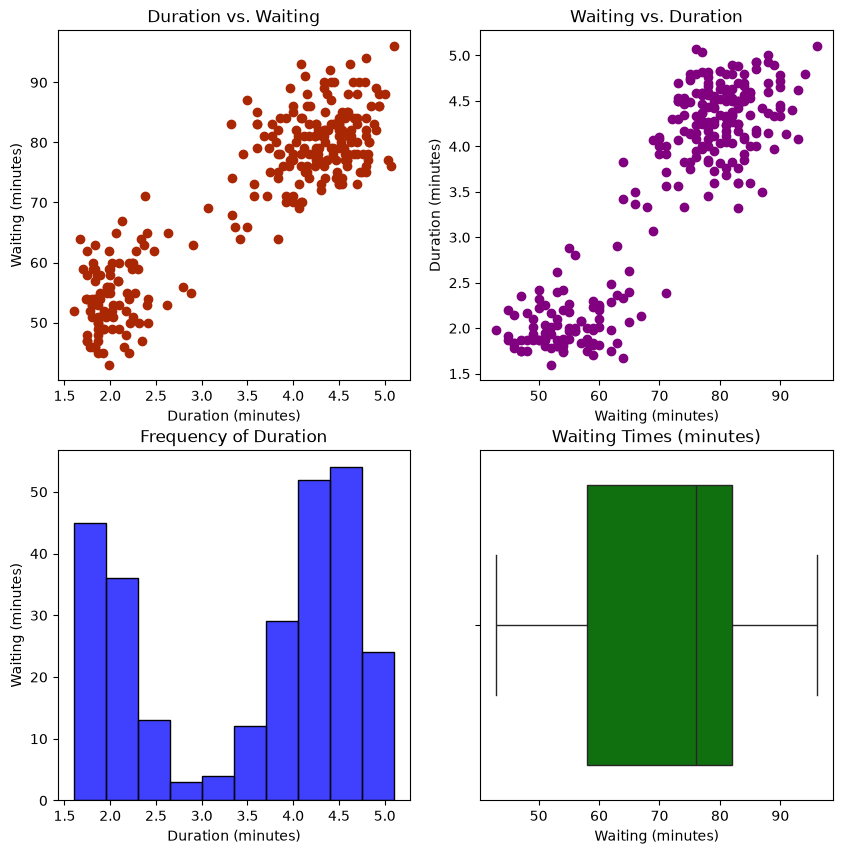

In [14]:
fig, axes = plt.subplots(2, 2, figsize = (10, 10))
axes[0,0].scatter(df["duration"], df["waiting"], color = "xkcd:rust red")
axes[0,1].scatter(df["waiting"], df["duration"], color = "purple")
axes[0,0].set_title("Duration vs. Waiting")
axes[0,0].set_xlabel("Duration (minutes)")
axes[0,0].set_ylabel("Waiting (minutes)")
axes[0,1].set_title("Waiting vs. Duration")
axes[0,1].set_xlabel("Waiting (minutes)")
axes[0,1].set_ylabel("Duration (minutes)")

sns.histplot(data=df, x = "duration", ax=axes[1,0], color = "blue")
sns.boxplot(data=df, x = "waiting", ax=axes[1,1], color = "green")
axes[1,0].set_title("Frequency of Duration")
axes[1,1].set_title("Waiting Times (minutes)")
axes[1,0].set_xlabel("Duration (minutes)")
axes[1,0].set_ylabel("Waiting (minutes)")
axes[1,1].set_xlabel("Waiting (minutes)")

plt.show()

Top left represents the clustered data for the duration of an eruption versus the amount of time it took between them, and top right is just a flipped version. The bottom right shows the frequency of a given duration of eruption, and the bottom left shows the statistical frequency of the waiting times.

I learned that the dataset has 2 major clusters, one where there's not much time between eruptions, and eruptions are short, and another where there's a lot of time between eruptions and eruptions are long. Could extrapolate that a longer wait time lets pressure build up for longer?